In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("../car_price_dataset_claude.csv")
#print(df.head())
#print(df.shape)
print(df.isnull().sum())
print(df.duplicated().sum())

age_years               0
mileage_km_thousands    0
engine_size_l           0
price_lakhs             0
dtype: int64
0


In [4]:
print(df.columns)
print(df.info())
print(df.describe())

Index(['age_years', 'mileage_km_thousands', 'engine_size_l', 'price_lakhs'], dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age_years             300 non-null    float64
 1   mileage_km_thousands  300 non-null    float64
 2   engine_size_l         300 non-null    float64
 3   price_lakhs           300 non-null    float64
dtypes: float64(4)
memory usage: 9.5 KB
None
        age_years  mileage_km_thousands  engine_size_l  price_lakhs
count  300.000000            300.000000     300.000000   300.000000
mean     7.427900            104.612033       2.413433    17.984533
std      4.415026             59.005140       0.850379     5.087732
min      0.080000              7.110000       1.010000     6.100000
25%      3.582500             53.677500       1.630000    13.935000
50%      7.675000            106.730000       2.360000    

In [5]:
df

,age_years,mileage_km_thousands,engine_size_l,price_lakhs
0,5.62,15.08,1.51,20.08
1,14.26,108.61,1.84,11.28
2,10.98,110.42,1.53,12.25
3,8.98,129.30,1.27,11.59
4,2.34,146.59,1.36,18.45
...,...,...,...,...
295,7.83,97.42,1.61,13.91
296,11.55,135.17,1.88,11.41
297,3.24,38.60,3.69,27.21
298,9.34,42.50,1.04,13.92


In [6]:
X = df.drop('price_lakhs',axis=1)
y=df['price_lakhs']
X,y

(     age_years  mileage_km_thousands  engine_size_l
 0         5.62                 15.08           1.51
 1        14.26                108.61           1.84
 2        10.98                110.42           1.53
 3         8.98                129.30           1.27
 4         2.34                146.59           1.36
 ..         ...                   ...            ...
 295       7.83                 97.42           1.61
 296      11.55                135.17           1.88
 297       3.24                 38.60           3.69
 298       9.34                 42.50           1.04
 299       1.28                 12.97           1.26
 
 [300 rows x 3 columns],
 0      20.08
 1      11.28
 2      12.25
 3      11.59
 4      18.45
        ...  
 295    13.91
 296    11.41
 297    27.21
 298    13.92
 299    25.30
 Name: price_lakhs, Length: 300, dtype: float64)

In [7]:
from sklearn.model_selection import train_test_split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

In [ ]:

Quick answer to your doubt: no, Ridge and Lasso aren't a type of polynomial 
regression — they're regularization techniques you can apply to any linear model.
When you apply them on top of polynomial features, that combo is often called 
"regularized polynomial regression," but Ridge/Lasso themselves are separate algorithms.

In [12]:
"""Code to test degree 1 vs 2 vs 3 yourself:"""

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

for d in [1, 2, 3,4,5,6,7,8,9]:
    poly = PolynomialFeatures(degree=d)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)
    
    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    pred = model.predict(X_test_poly)
    
    print(f"degree {d}: R2 = {r2_score(y_test, pred):.5f}")

"""Whichever degree gives the highest test R² (without it crashing at higher degrees) is your answer."""

degree 1: R2 = 0.95673
degree 2: R2 = 0.99281
degree 3: R2 = 0.97859
degree 4: R2 = 0.87094
degree 5: R2 = 0.71525
degree 6: R2 = 0.51442
degree 7: R2 = 0.40622
degree 8: R2 = 0.32582
degree 9: R2 = 0.27309


'Whichever degree gives the highest test R² (without it crashing at higher degrees) is your answer.'

In [10]:
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)


scaler = StandardScaler()
X_train_poly_s = scaler.fit_transform(X_train_poly)
X_test_poly_s = scaler.transform(X_test_poly)

In [11]:
model = LinearRegression()
model.fit(X_train_poly_s, y_train)
pred = model.predict(X_test_poly_s)

print(f"degree {d}: R2 = {r2_score(y_test, pred):.3f}")

degree 9: R2 = 0.993


In [21]:
from sklearn.linear_model import RidgeCV, LassoCV

ridge_cv = RidgeCV(alphas=[0.001, 0.01, 0.1, 1, 10, 100])
ridge_cv.fit(X_train_poly, y_train)
print("Best ridge alpha:", ridge_cv.alpha_)

lasso_cv = LassoCV(alphas=[0.001, 0.01, 0.1, 1, 10, 100])
lasso_cv.fit(X_train_poly, y_train)
print("Best lasso alpha:", lasso_cv.alpha_)

Best ridge alpha: 0.01
Best lasso alpha: 0.001


In [22]:
ridge = Ridge(alpha=0.01)
ridge.fit(X_train_poly_s, y_train)
ridge_pred = ridge.predict(X_test_poly_s)

print(f"degree {d}: R2 = {r2_score(y_test, ridge_pred):.3f}")

degree 9: R2 = 0.993


In [23]:
lasso = Lasso(alpha=0.001)
lasso.fit(X_train_poly_s, y_train)
lasso_pred = lasso.predict(X_test_poly_s)

print(f"degree {d}: R2 = {r2_score(y_test, lasso_pred):.3f}")

degree 9: R2 = 0.993


In [16]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [24]:
from sklearn.metrics import r2_score, mean_squared_error

print("Ridge RMSE:", mean_squared_error(y_test, ridge_pred)**0.5)

print("Lasso RMSE:", mean_squared_error(y_test, lasso_pred)**0.5)

Ridge RMSE: 0.4368160324261124
Lasso RMSE: 0.43558494507302353


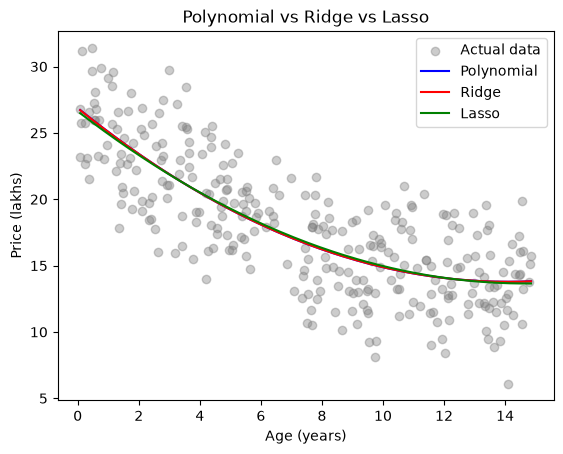

In [25]:
import matplotlib.pyplot as plt

X_age = df[['age_years']].values
y = df['price_lakhs'].values
sort_idx = X_age[:, 0].argsort()

poly = PolynomialFeatures(degree=2)
X_age_poly = poly.fit_transform(X_age)

lin = LinearRegression().fit(X_age_poly, y)
ridge = Ridge(alpha=1.0).fit(X_age_poly, y)
lasso = Lasso(alpha=0.1).fit(X_age_poly, y)

plt.scatter(X_age, y, color='gray', alpha=0.4, label='Actual data')
plt.plot(X_age[sort_idx], lin.predict(X_age_poly)[sort_idx], color='blue', label='Polynomial')
plt.plot(X_age[sort_idx], ridge.predict(X_age_poly)[sort_idx], color='red', label='Ridge')
plt.plot(X_age[sort_idx], lasso.predict(X_age_poly)[sort_idx], color='green', label='Lasso')

plt.xlabel('Age (years)')
plt.ylabel('Price (lakhs)')
plt.legend()
plt.title('Polynomial vs Ridge vs Lasso')
plt.show()